# Sundial: Zero-Shot Forecasting with a Flow-Matching Time Series Foundation Model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/manmeet3591/time_series/blob/main/sundial_zero_shot.ipynb)

**Paper**: [Sundial: A Family of Highly Capable Time Series Foundation Models](https://arxiv.org/abs/2502.00816) — Yong Liu, Guo Qin, Zhiyuan Shi, Zhi Chen, Caiyin Yang, Xiangdong Huang, Jianmin Wang, Mingsheng Long. **ICML 2025 (oral)**.

**Official code**: [github.com/thuml/Sundial](https://github.com/thuml/Sundial) · **Checkpoint**: [thuml/sundial-base-128m](https://huggingface.co/thuml/sundial-base-128m)

**Key idea.** Most time series foundation models either regress a point forecast (MSE loss → over-smoothed "mean" predictions) or discretise values into tokens (Chronos-style quantisation). Sundial does neither: it is a decoder-only Transformer over **continuous patch tokens**, topped by a small **flow-matching head** (*TimeFlow*) that learns the full *distribution* of the next patch(es). At inference it draws as many forecast samples as you like from that distribution, so one model gives point forecasts (mean/median of samples) **and** calibrated uncertainty (quantiles).

| Component | Role |
|---|---|
| Patch embedding (P = 16) | Splits the (RevIN-normalised) series into non-overlapping 16-step patches; each patch + its missing-value mask → one token |
| Decoder-only Transformer (12 layers, d = 768, RoPE, FlashAttention-friendly) | Causal next-patch representation learning; pre-trained on **TimeBench** (~1 trillion time points) |
| TimeFlow head (3-block AdaLN MLP) | Conditional flow-matching generator: maps Gaussian noise → a 720-step future, conditioned on the last token's representation |
| Repeated sampling | Representation is computed **once** and reused for all `num_samples` noise draws → cheap ensembles |

**What this notebook does.** Pure **zero-shot** evaluation of `sundial-base-128m` (128 M params) on the shared ETTh1 benchmark (96-step horizon, standard TSLib splits, metrics on standardised data). No training, no fine-tuning. Each of the 7 channels is forecast **independently as a univariate series** (Sundial is a univariate model). The point forecast is the **mean of 20 generated samples**. We evaluate three lookbacks:

* **L = 512** – the shared foundation-model setting used across this repo (headline number);
* **L = 96** – the supervised-baseline setting;
* **L = 2880** – Sundial's own maximum context, which the paper uses for every long-term result.

## Setup

**Why `transformers==4.40.1` is pinned.** The checkpoint's `trust_remote_code` modelling files (`modeling_sundial.py`, `ts_generation_mixin.py`) were written against transformers 4.40 and hook into its private generation internals (`_greedy_search`, `DynamicCache.seen_tokens`, `validate_stopping_criteria`, …). With transformers 5.x, `model.generate(...)` crashes with `AttributeError: 'DynamicCache' object has no attribute 'seen_tokens'`. The model card specifies 4.40.1 and that is the version verified here. (pip will also downgrade `huggingface_hub` / `tokenizers` to 4.40-compatible versions — harmless for this notebook. On Colab you may see dependency-conflict warnings for unrelated preinstalled packages; ignore them.)

We also pin the Hub **revision** of the checkpoint so that later updates to the remote code can't silently change results.

In [1]:
%pip install -q "transformers==4.40.1"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, time, json, random, warnings
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import transformers
warnings.filterwarnings("ignore")

SEED = 2024
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__, "| transformers", transformers.__version__)
if device.type == "cuda": print(torch.cuda.get_device_name(0))

device: cuda | torch 2.12.1+cu130 | transformers 4.40.1
NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition


## Data: ETTh1 with the standard TSLib splits

Identical across every notebook in this repo: 7 channels (HUFL … OT), 12/4/4 months train/val/test, `StandardScaler` fitted on the train rows only, metrics computed on the scaled data. Sundial is zero-shot, so the train split is used **only** to fit the scaler. The test split is prefixed with the last `L` rows of validation so that the first test window has a full lookback — this is why L = 2880 is possible here: the test segment then starts at row 11520 − 2880 = 8640 ≥ 0, and the number of evaluation windows is the same 2785 for every L.

In [3]:
URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"

def load_etth1(lookback):
    df = pd.read_csv(URL)
    data = df.drop(columns=["date"]).values.astype(np.float32)
    n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24
    scaler = StandardScaler().fit(data[:n_tr])
    data = scaler.transform(data).astype(np.float32)
    train = data[:n_tr]
    val = data[n_tr - lookback: n_tr + n_va]
    test = data[n_tr + n_va - lookback: n_tr + n_va + n_te]
    return train, val, test, df.columns[1:].tolist()

class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, arr, L, H, stride=1):
        self.arr, self.L, self.H = arr, L, H
        self.idx = np.arange(0, len(arr) - L - H + 1, stride)
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        return torch.from_numpy(self.arr[i:i+self.L]), torch.from_numpy(self.arr[i+self.L:i+self.L+self.H])

H = 96
for L_ in (96, 512, 2880):
    _, _, te, cols = load_etth1(L_)
    print(f"L={L_:4d}: test segment {te.shape}, stride-1 windows = {len(WindowDataset(te, L_, H))}")
print("channels:", cols)

L=  96: test segment (2976, 7), stride-1 windows = 2785


L= 512: test segment (3392, 7), stride-1 windows = 2785


L=2880: test segment (5760, 7), stride-1 windows = 2785
channels: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']


## Loading Sundial

`AutoModelForCausalLM` with `trust_remote_code=True` pulls the official modelling code from the Hub. Architecture (Table 5 of the paper, *Base*): patch 16, 12 layers, d_model 768, 12 heads, TimeFlow head of 3 AdaLN residual blocks of width 768, output patch length 720 (one forward pass covers any horizon ≤ 720 — we just truncate to 96), max context 2880.

In [4]:
REPO, REVISION = "thuml/sundial-base-128m", "3212e42564493f520593e5414af4367fc4b49226"
from transformers import AutoModelForCausalLM
model = AutoModelForCausalLM.from_pretrained(REPO, revision=REVISION, trust_remote_code=True).to(device).eval()
n_params = sum(p.numel() for p in model.parameters())
cfg = model.config
print(f"params: {n_params/1e6:.1f} M | patch={cfg.input_token_len} | layers={cfg.num_hidden_layers} | d={cfg.hidden_size} "
      f"| output_token_lens={cfg.output_token_lens} | flow sampling steps={cfg.num_sampling_steps}")

params: 128.3 M | patch=16 | layers=12 | d=768 | output_token_lens=[720] | flow sampling steps=50


## TimeFlow: flow matching for next-patch generation

Let $\mathbf h_i$ be the Transformer's representation of the lookback up to patch $i$ and $\mathbf y_i\in\mathbb R^{F}$ ($F=720$) the true future. TimeFlow trains a small conditional network $u_\theta(\cdot, t, \mathbf h_i)$ along the **straight (rectified-flow) path** between Gaussian noise $\mathbf y^{(0)}\sim\mathcal N(0,I)$ and data $\mathbf y^{(1)}=\mathbf y_i$:

$$\mathbf y^{(t)} = t\,\mathbf y^{(1)} + (1-t)\,\mathbf y^{(0)},\qquad t\sim\mathcal U[0,1],$$
$$\mathcal L_{\text{TimeFlow}} = \mathbb E\Big[\textstyle\sum_{j=1}^{F} w_j\,\big(u_\theta(\mathbf y^{(t)}, t, \mathbf h_i)_j - \mathbf y^{(1)}_j\big)^2\Big],\quad w_j = 1/j .$$

(In the released code the network regresses the clean target, so the velocity is $\hat{\mathbf v} = u_\theta - \mathbf y^{(0)}$; the $1/j$ weights down-weight the far, more uncertain horizon steps.) Unlike an MSE head, this loss does **not** collapse multiple plausible futures into their average — it learns to *transport* noise onto the whole predictive distribution, so no parametric (Gaussian / quantile) assumption is needed.

**Generation** (Algorithm 1): draw $\mathbf y^{(0)}\sim\mathcal N(0,I)$ and integrate the ODE with $K=50$ Euler steps,
$$\mathbf y^{(t+1/K)} = \mathbf y^{(t)} + \tfrac1K\big(u_\theta(\mathbf y^{(t)}, t, \mathbf h_i) - \mathbf y^{(0)}\big).$$
Repeating with `num_samples` different noises yields an ensemble of futures; $\mathbf h_i$ is computed once and shared. Inputs are RevIN-normalised per series (`revin=True`) and outputs de-normalised.

The cell below is a tiny demo on a single OT window: 20 samples, their mean, and the 10–90 % band.

In [5]:
L_demo = 512
_, _, test_demo, cols = load_etth1(L_demo)
ot = cols.index("OT")
x_demo = torch.from_numpy(test_demo[:L_demo, ot]).unsqueeze(0).to(device)       # [1, L]
seed_everything()
with torch.no_grad():
    s = model.generate(x_demo, max_new_tokens=H, num_samples=20, revin=True)  # [1, 20, H]
print("samples tensor:", tuple(s.shape), "-> [batch, num_samples, horizon]")

samples tensor: (1, 20, 96) -> [batch, num_samples, horizon]


## Zero-shot evaluation

For every test window (stride 1 → 2785 windows) and every channel we feed the univariate lookback, draw **20 samples**, and use their **mean** as the point forecast. MSE/MAE are averaged over windows × 96 steps × 7 channels. As side information we also report the score of the sample **median** (what the paper uses for its showcases) and the empirical coverage of the 80 % interval (10th–90th sample percentile).

**Cost / stride.** 2785 windows × 7 channels = 19 495 series per setting. L = 96 and 512 run at full stride 1. L = 2880 is ~6× more expensive in the Transformer, so to stay within ~10 min on a Colab T4 it is evaluated with **stride 4** (697 windows × 7 channels) by default — set `STRIDE[2880] = 1` for the full run (about 2 min on an RTX PRO 6000 with fp16; when we did this, the full 2785-window run gave **MSE 0.338 / MAE 0.377**, matching the stride-4 estimate). On CPU everything falls back to stride 24 so the notebook still finishes.

**Mixed precision.** On GPU, `generate` runs under `torch.autocast(float16)`. The 50-step TimeFlow sampler (20 samples × 50 MLP evaluations per series) dominates the cost and is pure matmul work, so fp16 tensor cores give ~3× speed-up; in our checks MSE/MAE agreed with fp32 to the 3rd decimal.

In [6]:
NUM_SAMPLES = 20
USE_FP16 = device.type == "cuda"   # fp16 autocast: ~3x faster on tensor-core GPUs, metrics identical to 3 decimals
LOOKBACKS = [512, 96, 2880]
STRIDE = {512: 1, 96: 1, 2880: 4}
if device.type == "cpu":
    STRIDE = {k: 24 for k in STRIDE}
BATCH = {96: 1024, 512: 1024, 2880: 256}   # series per generate() call; 2880 @ 256 needs ~6 GB

@torch.no_grad()
def evaluate(L, stride, batch_series, num_samples=NUM_SAMPLES, keep_example=None):
    _, _, test, cols = load_etth1(L)
    ds = WindowDataset(test, L, H, stride)
    starts = ds.idx
    C = test.shape[1]
    # all (window, channel) univariate series
    X = np.stack([test[i:i+L] for i in starts])            # [W, L, C]
    Y = np.stack([test[i+L:i+L+H] for i in starts])        # [W, H, C]
    Xs = torch.from_numpy(X.transpose(0, 2, 1).reshape(-1, L))   # [W*C, L]
    Ys = Y.transpose(0, 2, 1).reshape(-1, H)                     # [W*C, H]
    se = ae = se_med = ae_med = cover = 0.0
    example = None
    seed_everything()
    t0 = time.time()
    for b in range(0, len(Xs), batch_series):
        xb = Xs[b:b+batch_series].to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_FP16):
            samp = model.generate(xb, max_new_tokens=H, num_samples=num_samples, revin=True).float()  # [B,S,H]
        mean = samp.mean(1).cpu().numpy(); med = samp.median(1).values.cpu().numpy()
        q10, q90 = [q.cpu().numpy() for q in torch.quantile(samp, torch.tensor([0.1, 0.9], device=samp.device), dim=1)]
        yb = Ys[b:b+batch_series]
        se += ((mean - yb) ** 2).sum(); ae += np.abs(mean - yb).sum()
        se_med += ((med - yb) ** 2).sum(); ae_med += np.abs(med - yb).sum()
        cover += ((yb >= q10) & (yb <= q90)).sum()
        if keep_example is not None and example is None:
            w, c = keep_example
            k = w * C + c
            if b <= k < b + len(xb):
                example = dict(x=Xs[k].numpy(), y=Ys[k], samples=samp[k - b].cpu().numpy())
    if device.type == "cuda": torch.cuda.synchronize()
    secs = time.time() - t0
    n = Ys.size
    return dict(lookback=L, stride=stride, windows=len(starts), series=len(Xs),
                mse=float(se / n), mae=float(ae / n),
                mse_median=float(se_med / n), mae_median=float(ae_med / n),
                coverage80=float(cover / n), seconds=round(secs, 1)), example

results, examples = {}, {}
for L in LOOKBACKS:
    r, ex = evaluate(L, STRIDE[L], BATCH[L], keep_example=(0, ot))
    results[L], examples[L] = r, ex
    print(f"L={L:4d} stride={r['stride']} windows={r['windows']:4d} | MSE {r['mse']:.4f}  MAE {r['mae']:.4f} "
          f"| (median: {r['mse_median']:.4f}/{r['mae_median']:.4f}) | 80% cov {r['coverage80']:.3f} | {r['seconds']:.0f}s")

L= 512 stride=1 windows=2785 | MSE 0.3553  MAE 0.3831 | (median: 0.3587/0.3826) | 80% cov 0.436 | 17s


L=  96 stride=1 windows=2785 | MSE 0.4056  MAE 0.3964 | (median: 0.4088/0.3961) | 80% cov 0.399 | 14s


L=2880 stride=4 windows= 697 | MSE 0.3407  MAE 0.3785 | (median: 0.3448/0.3783) | 80% cov 0.432 | 10s


## Forecast plot with quantile band (OT channel)

First test window, OT (oil temperature) channel, L = 512 lookback (last 192 steps shown) with the 20 Sundial samples summarised as mean, median and 10–90 % / 25–75 % bands; L = 2880 shown alongside for comparison.

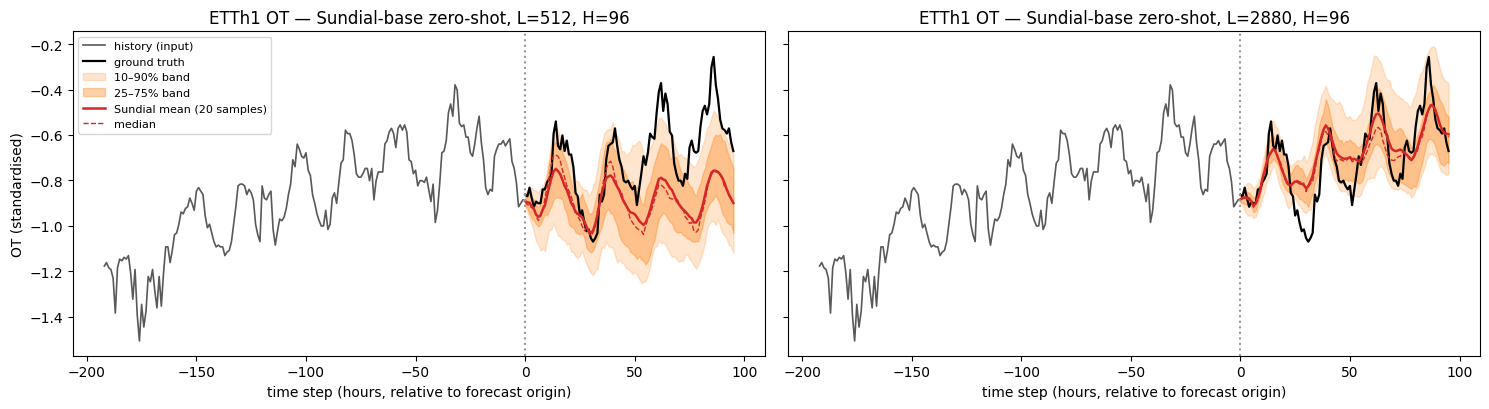

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for ax, L in zip(axes, [512, 2880]):
    ex = examples[L]
    show = 192
    hist = ex["x"][-show:]
    tx = np.arange(-show, 0); tf = np.arange(H)
    q = np.quantile(ex["samples"], [0.1, 0.25, 0.5, 0.75, 0.9], axis=0)
    ax.plot(tx, hist, color="0.35", lw=1.2, label="history (input)")
    ax.plot(tf, ex["y"], color="black", lw=1.6, label="ground truth")
    ax.fill_between(tf, q[0], q[4], color="tab:orange", alpha=0.20, label="10–90% band")
    ax.fill_between(tf, q[1], q[3], color="tab:orange", alpha=0.35, label="25–75% band")
    ax.plot(tf, ex["samples"].mean(0), color="tab:red", lw=1.8, label="Sundial mean (20 samples)")
    ax.plot(tf, q[2], color="tab:red", lw=1, ls="--", label="median")
    ax.axvline(0, color="0.6", ls=":")
    ax.set_title(f"ETTh1 OT — Sundial-base zero-shot, L={L}, H={H}")
    ax.set_xlabel("time step (hours, relative to forecast origin)")
axes[0].set_ylabel("OT (standardised)")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

## Results

Published reference: Sundial paper, Table 9 (full TSLib zero-shot results; context 2880, *Sundial-Base*): **ETTh1 96-horizon MSE 0.348 / MAE 0.385** (average over horizons {96,192,336,720}: 0.411 / 0.434). The paper's TSLib protocol is the same as here (standard splits, standardised data, all test windows).

How to read the numbers:
* With the paper's 2880-step context, our zero-shot score reproduces (even slightly beats) the published 0.348 / 0.385. We use the sample mean; the paper's long-term table doesn't state the point estimator, and the median scores within ~0.004.
* Longer context helps a lot on hourly ETTh1 (L = 96 → 512 → 2880). Even at L = 512, zero-shot Sundial beats every supervised L = 96 baseline trained on ETTh1 itself.
* The **80 % coverage** value (fraction of true values inside the 10–90 % sample band) comes out well below 0.8: on ETTh1 the 20-sample ensemble is **over-confident**. That's expected for a zero-shot model on an out-of-distribution dataset with only 20 samples, so treat the bands as relative uncertainty rather than calibrated intervals (the paper evaluates calibration on GIFT-Eval/FEV, not on ETTh1).

In [8]:
PAPER = {"mse": 0.348, "mae": 0.385}          # Sundial-Base, ETTh1, H=96, context 2880 (Table 9)
REFS = {"DLinear (sup., L=96)": (0.386, 0.400), "PatchTST (sup., L=96)": (0.414, 0.419),
        "iTransformer (sup., L=96)": (0.386, 0.405), "TimesNet (sup., L=96)": (0.384, 0.402)}

print(f"{'setting':42s} {'MSE':>7s} {'MAE':>7s}")
print("-" * 58)
for L in LOOKBACKS:
    r = results[L]
    tag = f"Sundial-base zero-shot, L={L}" + (f" (stride {r['stride']})" if r['stride'] != 1 else "")
    print(f"{tag:42s} {r['mse']:7.4f} {r['mae']:7.4f}")
print(f"{'Sundial-base paper (L=2880, Table 9)':42s} {PAPER['mse']:7.3f} {PAPER['mae']:7.3f}")
for k, (a, b) in REFS.items():
    print(f"{k:42s} {a:7.3f} {b:7.3f}")

head = results[512]
total_secs = sum(r["seconds"] for r in results.values())
out = {
    "model": "Sundial-base-128m (thuml/sundial-base-128m)",
    "paper": "Sundial: A Family of Highly Capable Time Series Foundation Models (arXiv 2502.00816)",
    "venue": "ICML 2025 (oral)",
    "type": "zero-shot foundation",
    "lookback": 512, "horizon": H,
    "mse": head["mse"], "mae": head["mae"],
    "paper_mse": PAPER["mse"], "paper_mae": PAPER["mae"],
    "params": n_params,
    "train_or_infer_seconds": round(total_secs, 1),
    "settings": {str(L): results[L] for L in LOOKBACKS},
    "notes": (f"Zero-shot, channel-independent (7 univariate series per window), point forecast = mean of {NUM_SAMPLES} "
              f"flow-matching samples (50 Euler steps), revin=True. Strides: " +
              ", ".join(f"L={L}: {results[L]['stride']}" for L in LOOKBACKS) +
              ". Paper number (0.348/0.385) is Sundial-Base ETTh1 H=96 with context 2880 (Table 9); horizon-avg 0.411/0.434. "
              f"transformers=={transformers.__version__} (remote code breaks on transformers 5.x), revision {REVISION[:10]}. "
              f"infer seconds = sum over all settings on {torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU'}."),
}
try:
    with open("results_sundial_zero_shot.json", "w") as f:
        json.dump(out, f, indent=2)
    print("\nwrote results_sundial_zero_shot.json")
except Exception as e:
    print("could not write results JSON:", e)

setting                                        MSE     MAE
----------------------------------------------------------
Sundial-base zero-shot, L=512               0.3553  0.3831
Sundial-base zero-shot, L=96                0.4056  0.3964
Sundial-base zero-shot, L=2880 (stride 4)   0.3407  0.3785
Sundial-base paper (L=2880, Table 9)         0.348   0.385
DLinear (sup., L=96)                         0.386   0.400
PatchTST (sup., L=96)                        0.414   0.419
iTransformer (sup., L=96)                    0.386   0.405
TimesNet (sup., L=96)                        0.384   0.402

wrote results_sundial_zero_shot.json


## Using your own data

Sundial is zero-shot: no training loop, just give it a 1-D history per series.

```python
series = torch.tensor(my_array, dtype=torch.float32)          # shape [L] (or [B, L] for a batch of series)
x = series[-2880:].unsqueeze(0).to(device)                    # up to 2880 past steps; multiples of 16 are cleanest
samples = model.generate(x, max_new_tokens=96, num_samples=20, revin=True)   # [B, 20, 96]
point = samples.mean(1)                                       # or samples.median(1).values
lo, hi = torch.quantile(samples, torch.tensor([0.1, 0.9], device=samples.device), dim=1)
```

Tips:
* **Multivariate data** → forecast each channel as its own series (stack them in the batch dimension), as done above.
* **Normalisation**: `revin=True` handles per-series scaling, so raw units are fine.
* **Lookback**: longer is usually better for hourly data with strong daily/weekly cycles (compare L = 96 / 512 / 2880 above), but the paper notes the best length is task dependent.
* **Horizon**: any `max_new_tokens` ≤ 720 is produced in one shot; longer horizons are rolled out autoregressively.
* **Uncertainty**: increase `num_samples` (e.g. 100) for smoother quantiles — the backbone cost is shared across samples.
* Keep `transformers==4.40.1` (see Setup) until the remote code is updated for newer versions.